# Simulation over expected values of wealth
no shocks and default parameters, which obey the conditions in order to have phase transition with poorandrichattractor / poorattractorindefinitelyincreasing

In [ ]:
import sys
sys.path.append("/Users/sofiacattaneo/tesi-inequality/src")
import numpy as np
import matplotlib.pyplot as plt

print(sys.path)


['/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python311.zip', '/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11', '/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11/lib-dynload', '', '/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11/site-packages', '/Users/sofiacattaneo/tesi-inequality/src', '/Users/sofiacattaneo/tesi-inequality/src']


In [2]:
from parameters import *
from functions import *
from conditions import *
from distributions import *
from simulations_det import *


n_p_initial= 0.52168
np_fin= 0.52442
mean wealth at t= 0 :	 0.35007944369873745
mean wealth at t= 1 :	 0.6045292586630338
mean wealth at t= 6 :	 4.644175173808114
mean wealth at t= 9 :	 14.874568231269434
mean wealth at t= 12 :	 47.36248859116553
mean wealth at t= 20 :	 1033.1753984696775


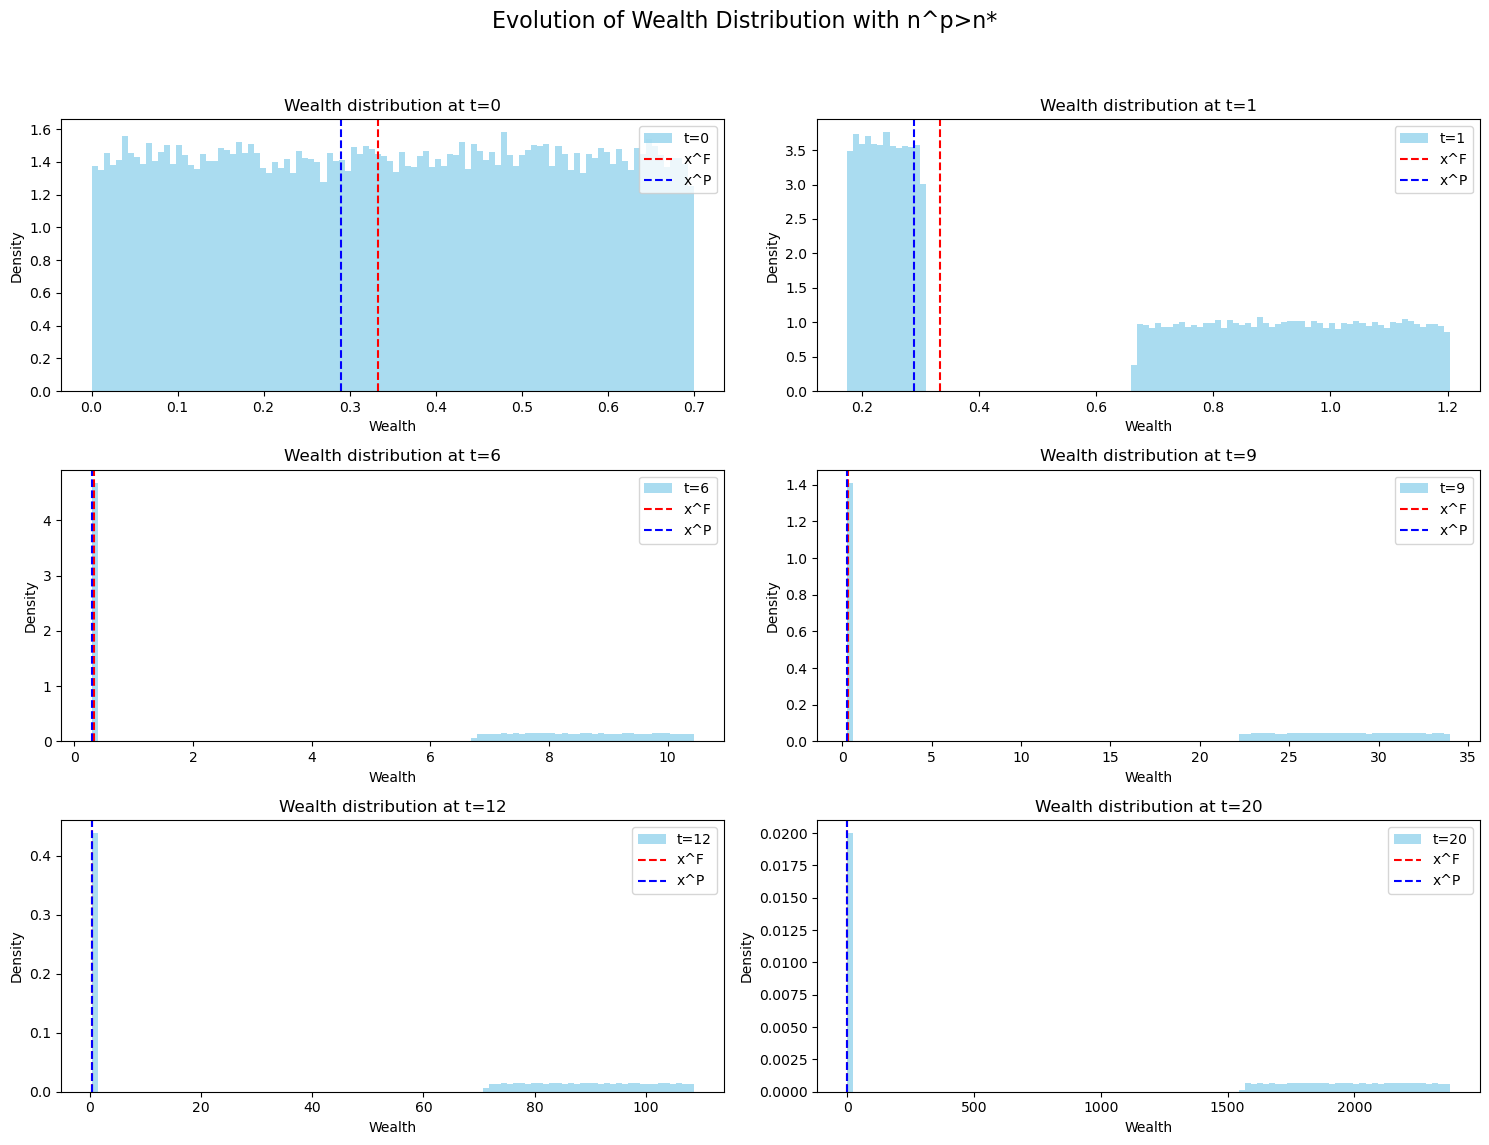

In [3]:
#simulazione con pochi poveri
T=20
yhigh=0.7
y = uniform_initial(N, low=0, high=yhigh)
n_p = np.mean(y > xF)
print('n_p_initial=', n_p)
history = simulate_det(lambda N: uniform_initial(N, low=0, high=yhigh), update_wealth, T)
n_p= np.mean(history[T]>xF)
print('np_fin=', n_p)

fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 6, 9, 12, 20]):
    t = t_val
    ax = axes[i]
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(), color='blue', linestyle='--', label="x^P")
    #ax.axvline(xr(n_p), color='green', linestyle='--', label="x^R")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', np.mean(history[t]))

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with n^p>n*', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

np_in = 0.16852
np_fin = 0.16852
mean wealth at t= 0 :	 0.20079735893222775
mean wealth at t= 1 :	 0.2893716039458411
mean wealth at t= 15 :	 0.616300412467729
mean wealth at t= 100 :	 0.9954762465873215
mean wealth at t= 200 :	 1.0093532441245703
mean wealth at t= 500 :	 1.0096367909373933


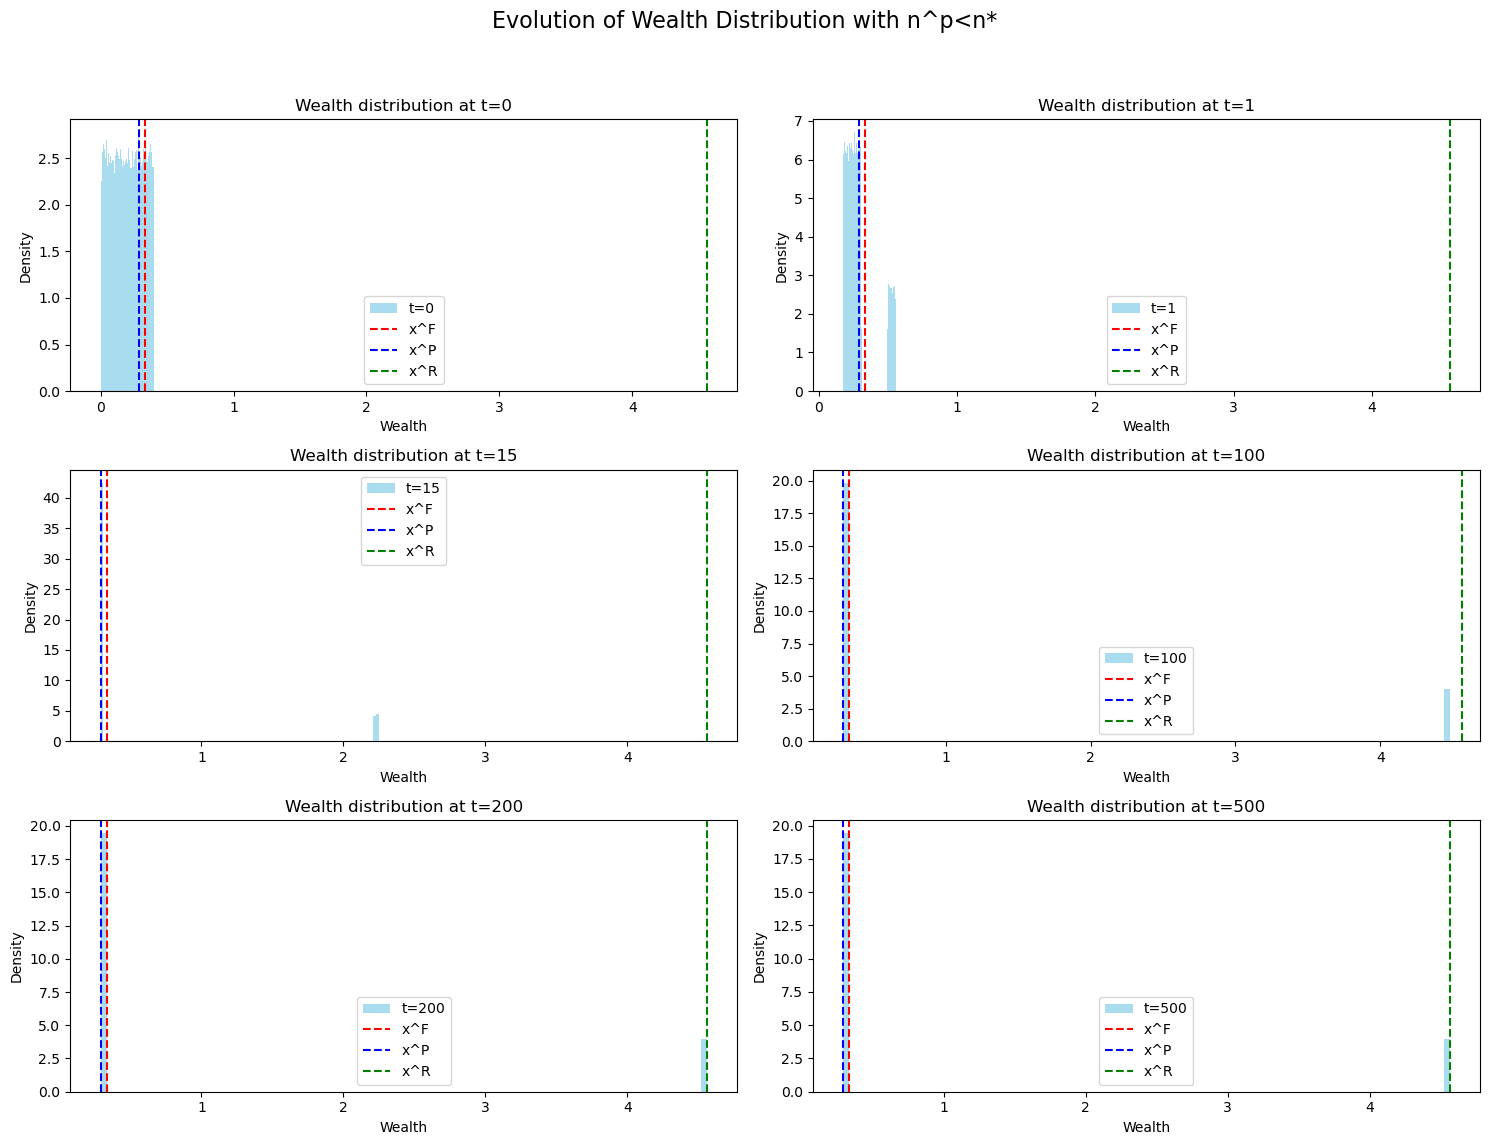

In [4]:
#simulazione con troppi poveri
T=500
history = simulate_det(lambda N: uniform_initial(N, low=0, high=0.4), update_wealth, T)
n_p= np.mean(history[0]> xF)
print('np_in =',n_p)
n_p= np.mean(history[T] > xF)
print('np_fin =',n_p)

fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 15, 100, 200, 500]):
    t = t_val
    ax = axes[i]
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(), color='blue', linestyle='--', label="x^P")
    ax.axvline(xr(n_p), color='green', linestyle='--', label="x^R")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', np.mean(history[t]))

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with n^p<n*', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

In [5]:
#simulazione con tantissimi poveri (per vedere come cambia l aumento di richezza)

T=500
history = simulate_det(lambda N: uniform_initial(N, low=0, high=0.2), update_wealth, T)
n_p= np.mean(history[0]> xF)
print('np_in =',n_p)
n_p= np.mean(history[T] > xF)
print('np_fin =',n_p)


np_in = 0.0
np_fin = 0.0


mean wealth at t= 0 :	 0.0999262092082811
mean wealth at t= 1 :	 0.21452081574187515
mean wealth at t= 15 :	 0.2894952790087035
mean wealth at t= 100 :	 0.2894954507857732


/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: divide by zero encountered in divide
  return n/db/n.sum(), bin_edges
/Users/sofiacattaneo/opt/anaconda3/envs/tesi/lib/python3.11/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


mean wealth at t= 200 :	 0.2894954507857732
mean wealth at t= 500 :	 0.2894954507857732


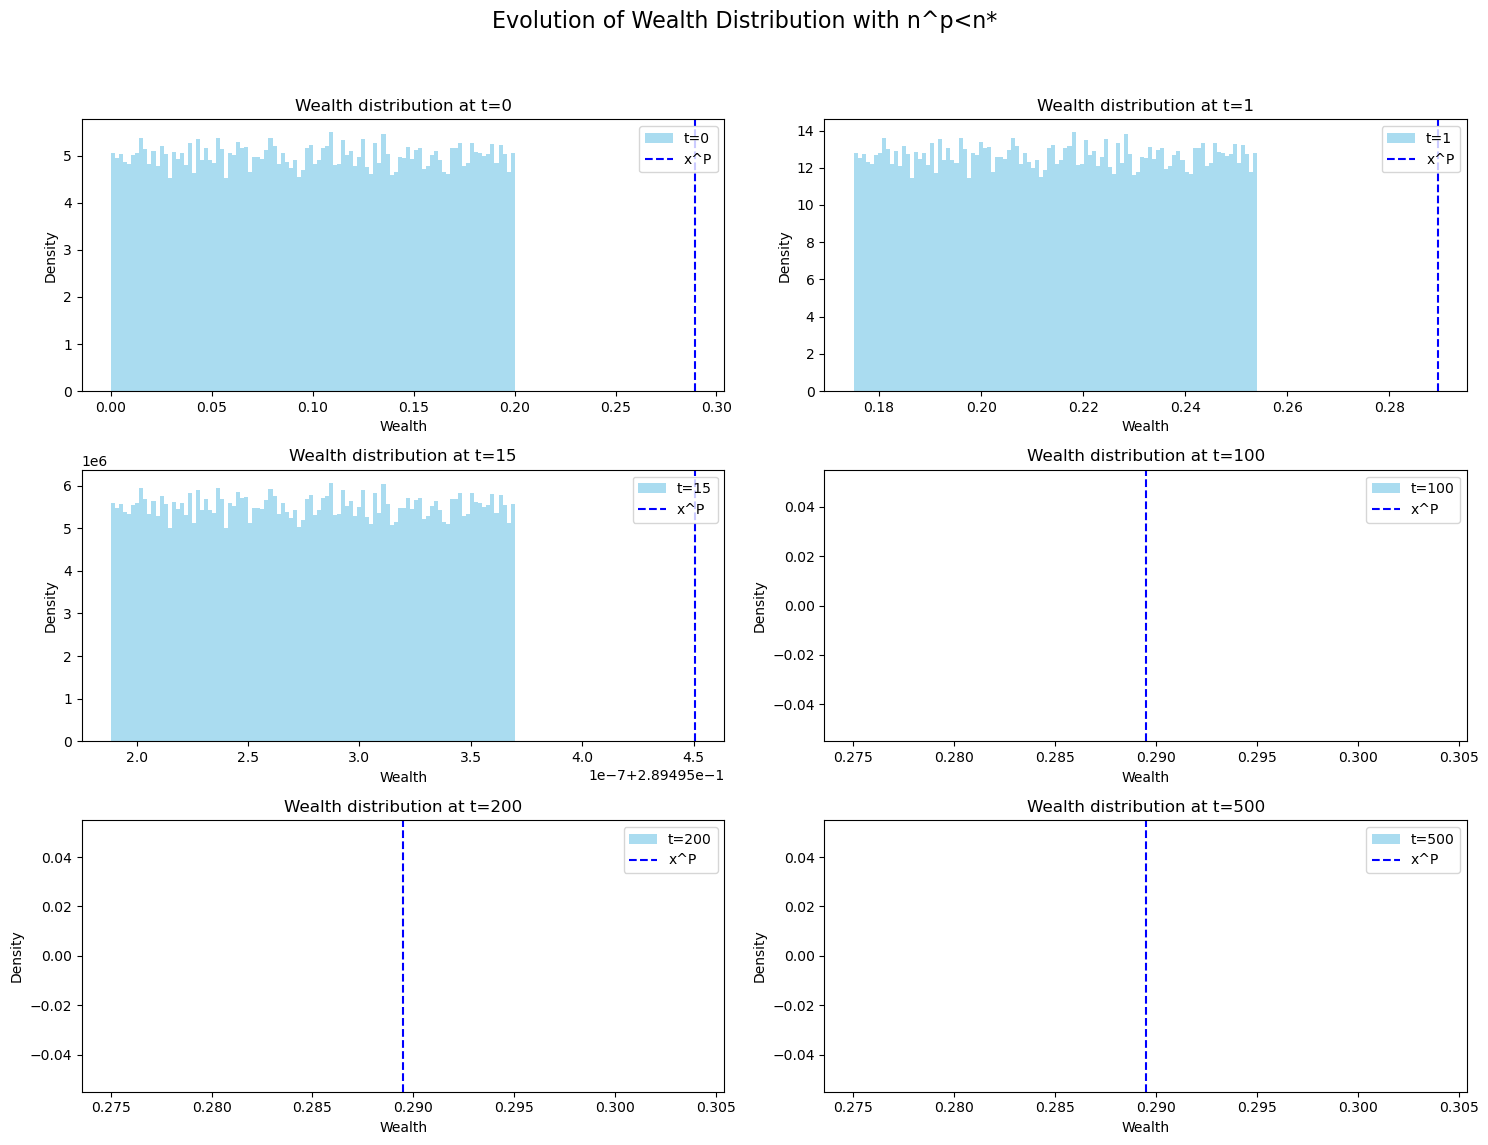

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 15, 100, 200, 500]):
    t = t_val
    ax = axes[i]
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    #ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(), color='blue', linestyle='--', label="x^P")
    #ax.axvline(xr(n_p), color='green', linestyle='--', label="x^R")
    #ax.axvline(mean, color='violet', linestyle='--', label="mean wealth")

    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', np.mean(history[t]))

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with n^p<n*', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()

In [ ]:
#simulazione con tanti sopra XP ma sotto xF
T=500
history = simulate_det(lambda N: uniform_initial(N, low=0.22, high=0.3), update_wealth, T)
n_p= np.mean(history[0]> xF)
print('np_in =',n_p)
n_p= np.mean(history[T] > xF)
print('np_fin =',n_p)


np_in = 0.0
np_fin = 0.0


mean wealth at t= 0 :	 0.26009374945420866
mean wealth at t= 1 :	 0.2205164061544865
mean wealth at t= 15 :	 0.2121212121214242
mean wealth at t= 100 :	 0.21212121212121202
mean wealth at t= 200 :	 0.21212121212121202
mean wealth at t= 500 :	 0.21212121212121202


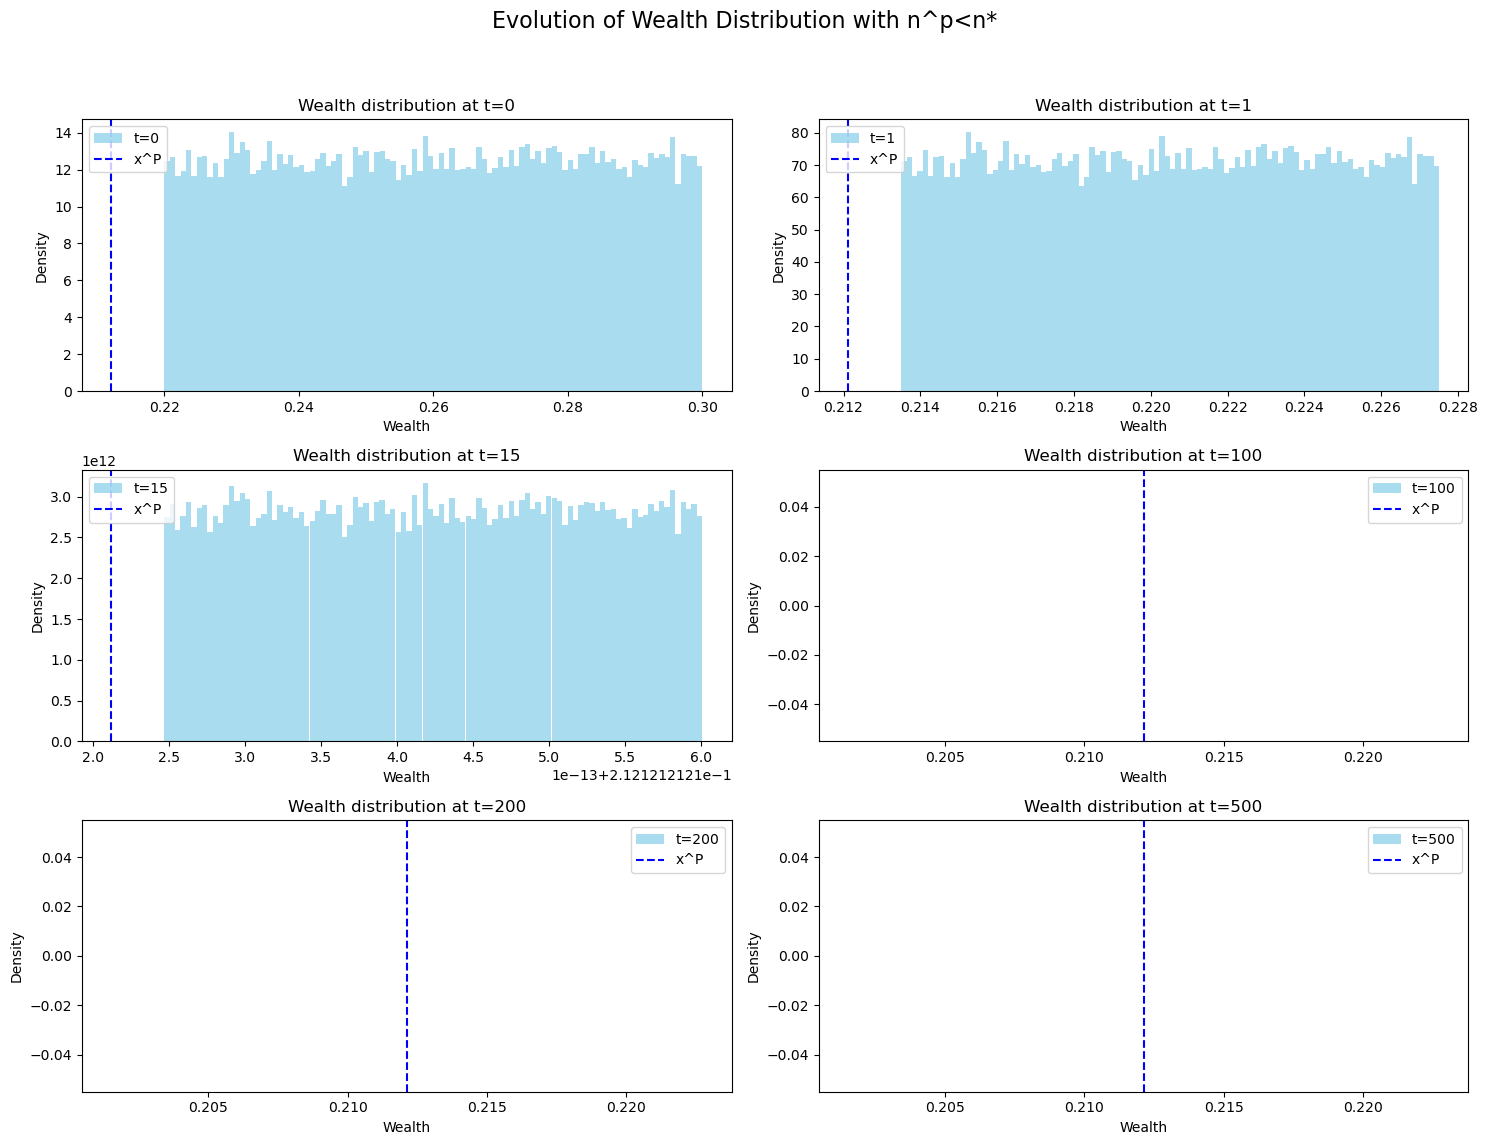

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(15, 12)) # Create a 3x2 grid of subplots
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, t_val in enumerate([0, 1, 15, 100, 200, 500]):
    t = t_val
    ax = axes[i]
    ax.hist(history[t], bins=100, alpha=0.7, label=f"t={t}", density=True, color='skyblue')
    #ax.axvline(xF, color='red', linestyle='--', label="x^F")
    ax.axvline(xp(), color='blue', linestyle='--', label="x^P")
    #ax.axvline(xr(n_p), color='green', linestyle='--', label="x^R")
    ax.legend()
    ax.set_title(f"Wealth distribution at t={t}")
    ax.set_xlabel("Wealth")
    ax.set_ylabel("Density")
    print('mean wealth at t=',t, ':\t', np.mean(history[t]))

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Evolution of Wealth Distribution with n^p<n*', fontsize=16) # Add a main title to the figure
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent overlapping titles/labels and make space for suptitle
plt.show()